# Phase 2: Liver segmentation (sama, patient 0)

| | sama's algorithms |
|---|---|
| Morphology | custom **ellipse 7x7 / 15x15** and hand-made **diamond 9x9** structuring elements |
| Method A | **Multi-Otsu** (4 classes) + morphology |
| Method B | **marker-controlled watershed** |
| Validation | Dice + IoU against the ground-truth liver |

In [1]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from scipy import ndimage as ndi
from skimage.filters import threshold_multiotsu, sobel
from skimage.segmentation import watershed

NAME = "sama"
ENH = "../phase1/outputs_sama/enhanced"          # Phase 1 output
GT = f"../data/slices/{NAME}"               # ground-truth masks
OUT = "outputs_sama"
FIGS = "../report/figures/sama"
FAILED = "../report/failed_cases/sama"
for d in [f"{OUT}/multiotsu", f"{OUT}/watershed", FIGS, FAILED]:
    os.makedirs(d, exist_ok=True)

files = sorted(glob.glob(f"{ENH}/*_enh.png"))
print(len(files), "enhanced slices found")

def load(enh_path):
    """Enhanced image (0-255) + ground-truth liver mask (True/False)."""
    sid = os.path.basename(enh_path).replace("_enh.png", "")      # e.g. p0_s60
    img = cv2.imread(enh_path, 0)
    gt = cv2.imread(f"{GT}/{sid}_liver.png", 0) > 0
    return sid, img, gt

def dice(pred, gt):
    """Dice = 2|A n B| / (|A| + |B|). 1 = perfect overlap, 0 = none."""
    return 2 * (pred & gt).sum() / (pred.sum() + gt.sum() + 1e-9)

def iou(pred, gt):
    """Jaccard / IoU = |A n B| / |A u B|."""
    return (pred & gt).sum() / ((pred | gt).sum() + 1e-9)

def keep_liver(mask):
    """Keep the biggest blob on the image's left side (the liver is on the patient's right = image left)."""
    n, labels, stats, centroids = cv2.connectedComponentsWithStats(mask.astype(np.uint8))
    best, best_area = 0, 0
    for i in range(1, n):                                   # 0 = background
        if centroids[i][0] < 0.6 * mask.shape[1] and stats[i, cv2.CC_STAT_AREA] > best_area:
            best, best_area = i, stats[i, cv2.CC_STAT_AREA]
    return labels == best if best else np.zeros(mask.shape, bool)

# example slice for the figures: the one with the largest liver
example = max(files, key=lambda f: load(f)[2].sum())
sid, img, gt = load(example)
print("example slice:", sid)

16 enhanced slices found
example slice: p0_s65


**Morphology:** erosion shrinks, dilation grows, opening (erode then dilate) removes specks, closing (dilate then erode) fills holes.

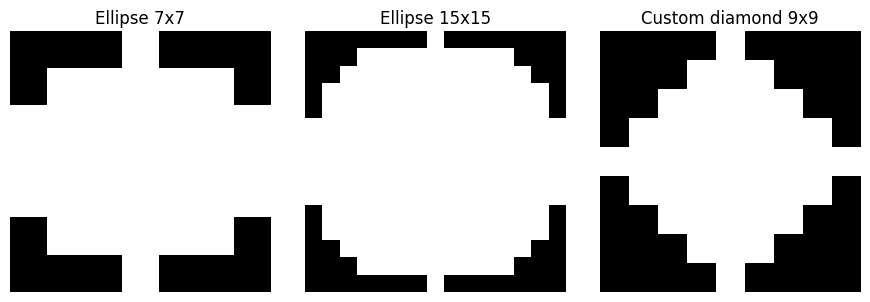

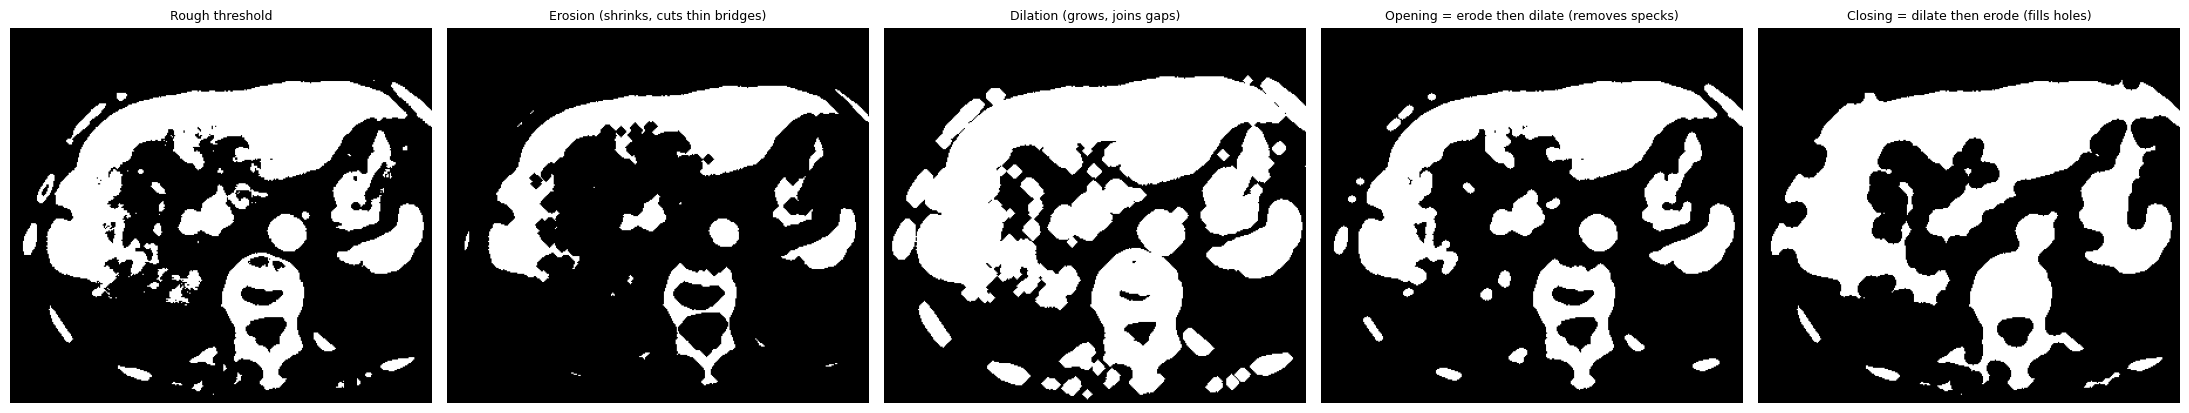

In [2]:
SE_ELLIPSE_7 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
SE_ELLIPSE_15 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
SE_DIAMOND_9 = np.array([[1 if abs(r - 4) + abs(c - 4) <= 4 else 0 for c in range(9)]
                         for r in range(9)], dtype=np.uint8)          # hand-made diamond shape

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, se, t in zip(ax, [SE_ELLIPSE_7, SE_ELLIPSE_15, SE_DIAMOND_9],
                    ["Ellipse 7x7", "Ellipse 15x15", "Custom diamond 9x9"]):
    a.imshow(se, cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

rough = (img > threshold_multiotsu(img, classes=4)[2]).astype(np.uint8)   # a rough bright-tissue mask
ops = {
    "Rough threshold": rough,
    "Erosion (shrinks, cuts thin bridges)": cv2.erode(rough, SE_DIAMOND_9),
    "Dilation (grows, joins gaps)": cv2.dilate(rough, SE_DIAMOND_9),
    "Opening = erode then dilate (removes specks)": cv2.morphologyEx(rough, cv2.MORPH_OPEN, SE_ELLIPSE_7),
    "Closing = dilate then erode (fills holes)": cv2.morphologyEx(rough, cv2.MORPH_CLOSE, SE_ELLIPSE_15),
}
fig, ax = plt.subplots(1, 5, figsize=(22, 5))
for a, (t, m) in zip(ax, ops.items()):
    a.imshow(m[100:420, 40:400], cmap="gray"); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_morphology.png", dpi=120); plt.show()

**Method A:** Multi-Otsu splits the image into 4 brightness classes; the brightest class holds the liver (and other organs), so morphology + `keep_liver` keep only the liver blob.

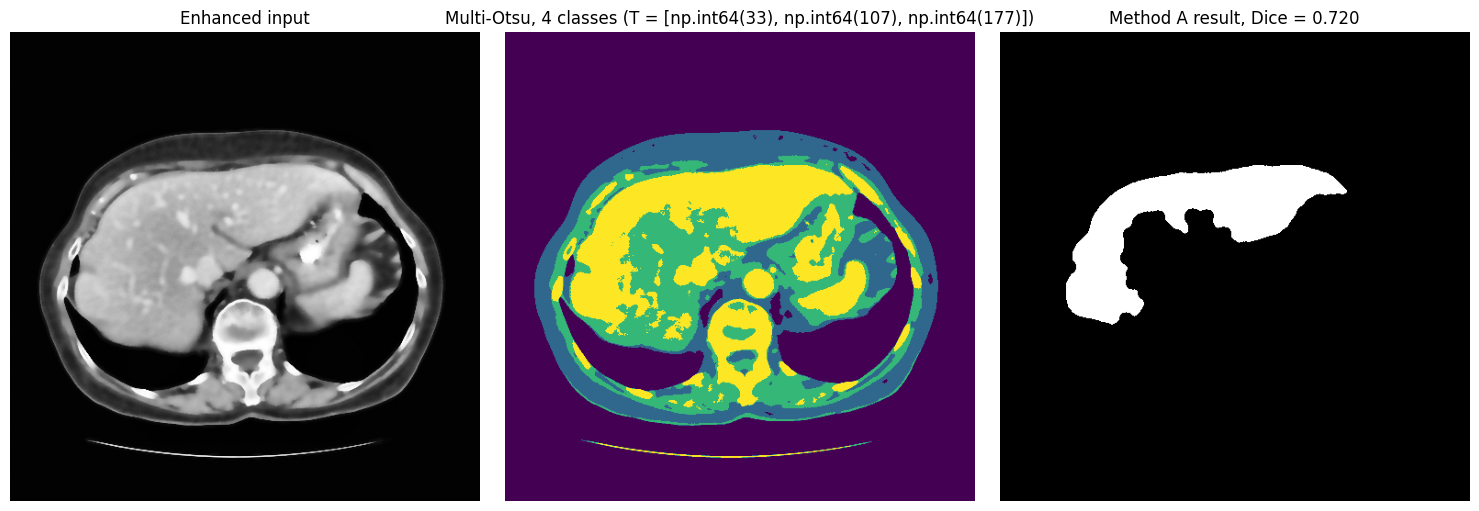

In [3]:
def segment_multiotsu(img):
    t = threshold_multiotsu(img, classes=4)                 # 3 thresholds -> 4 brightness classes
    mask = (img > t[2]).astype(np.uint8)                    # brightest class (liver, spleen, kidneys, bone...)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, SE_ELLIPSE_7)    # cut thin links to other organs
    mask = keep_liver(mask)                                  # keep the liver blob only
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_CLOSE, SE_ELLIPSE_15)  # smooth the edge
    return ndi.binary_fill_holes(mask > 0)                   # fill vessels / holes inside

t = threshold_multiotsu(img, classes=4)
classes = np.digitize(img, bins=t)
pred_a = segment_multiotsu(img)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("Enhanced input")
ax[1].imshow(classes, cmap="viridis"); ax[1].set_title(f"Multi-Otsu, 4 classes (T = {list(t)})")
ax[2].imshow(pred_a, cmap="gray"); ax[2].set_title(f"Method A result, Dice = {dice(pred_a, gt):.3f}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_method_a_multiotsu.png", dpi=120); plt.show()

**Method B:** markers = sure liver (solid core) and sure background (dark tissue + other organs); watershed floods the edge image from both, and the boundary forms where they meet.

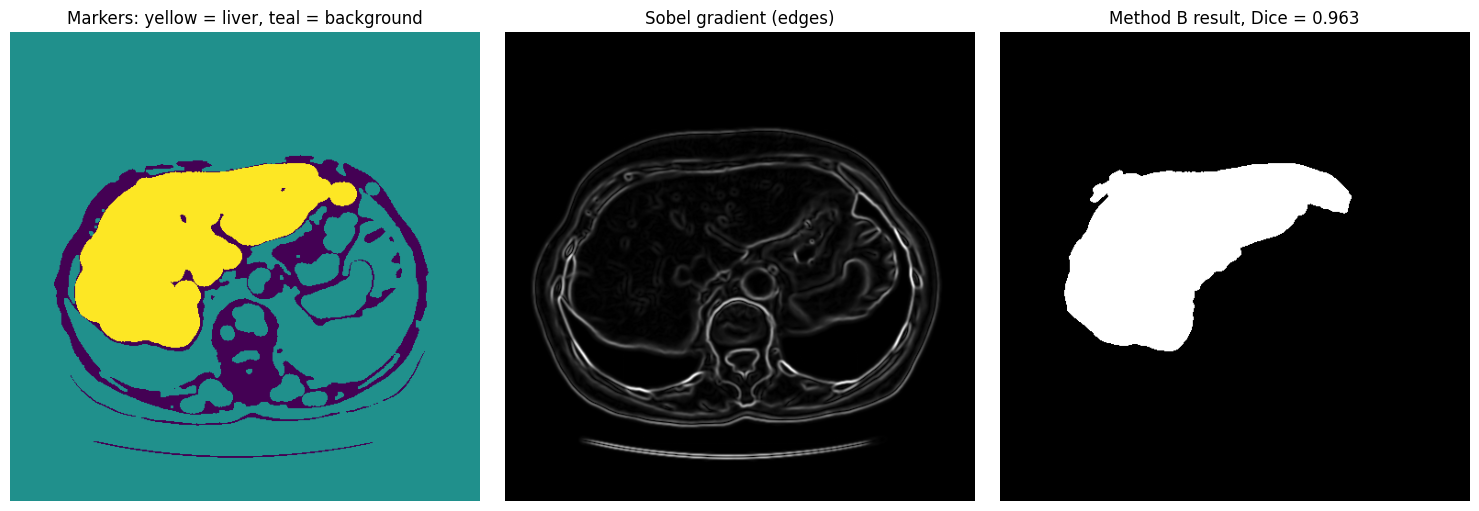

In [4]:
LIVER_LOW, LIVER_HIGH = 150, 225        # liver brightness range after Phase 1 (from the liver histogram)
DARK = 110                              # fat / air / muscle are darker than this

def segment_watershed(img, return_steps=False):
    band = ((img >= LIVER_LOW) & (img <= LIVER_HIGH)).astype(np.uint8)
    # 1. "sure liver" marker: a big opening keeps only the solid core of the liver
    core = keep_liver(cv2.morphologyEx(band, cv2.MORPH_OPEN,
                                       cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))))
    # 2. "sure background" marker: dark pixels + other bright organs away from the liver core
    near_core = cv2.dilate(core.astype(np.uint8), SE_ELLIPSE_15).astype(bool)
    other_organs = cv2.morphologyEx((band.astype(bool) & ~near_core).astype(np.uint8),
                                    cv2.MORPH_OPEN, SE_ELLIPSE_15) > 0
    dark = cv2.morphologyEx((img < DARK).astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)) > 0
    markers = np.zeros(img.shape, np.int32)
    markers[dark | other_organs] = 1                        # label 1 = background
    markers[core] = 2                                       # label 2 = liver
    # 3. flood the gradient image from the markers; the two floods meet on the strongest edges
    gradient = sobel(cv2.GaussianBlur(img, (5, 5), 0) / 255.0)
    labels = watershed(gradient, markers)
    mask = cv2.morphologyEx((labels == 2).astype(np.uint8), cv2.MORPH_OPEN, SE_ELLIPSE_7) > 0
    mask = ndi.binary_fill_holes(keep_liver(mask))
    return (mask, markers, gradient) if return_steps else mask

pred_b, markers, gradient = segment_watershed(img, return_steps=True)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(markers, cmap="viridis"); ax[0].set_title("Markers: yellow = liver, teal = background")
ax[1].imshow(gradient, cmap="gray"); ax[1].set_title("Sobel gradient (edges)")
ax[2].imshow(pred_b, cmap="gray"); ax[2].set_title(f"Method B result, Dice = {dice(pred_b, gt):.3f}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_method_b_watershed.png", dpi=120); plt.show()

In [5]:
rows = []
for f in files:
    sid, img, gt = load(f)
    for method, fn in [("multiotsu", segment_multiotsu), ("watershed", segment_watershed)]:
        pred = fn(img)
        cv2.imwrite(f"{OUT}/{method}/{sid}_liver_pred.png", pred.astype(np.uint8) * 255)
        rows.append({"slice": sid, "method": method, "Dice": dice(pred, gt), "IoU": iou(pred, gt),
                     "GT liver pixels": int(gt.sum())})

results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/phase2_metrics.csv", index=False)
print(results.groupby("method")[["Dice", "IoU"]].agg(["mean", "std", "min"]).round(3))
print("\nPer slice Dice:")
print(results.pivot(index="slice", columns="method", values="Dice").round(3))

            Dice                  IoU              
            mean    std    min   mean    std    min
method                                             
multiotsu  0.797  0.225  0.000  0.699  0.217  0.000
watershed  0.913  0.077  0.678  0.849  0.118  0.513

Per slice Dice:
method  multiotsu  watershed
slice                       
p0_s46      0.000      0.893
p0_s56      0.838      0.845
p0_s57      0.781      0.883
p0_s58      0.762      0.895
p0_s59      0.780      0.924
p0_s60      0.936      0.940
p0_s61      0.949      0.959
p0_s62      0.803      0.967
p0_s65      0.720      0.963
p0_s66      0.827      0.962
p0_s67      0.933      0.975
p0_s68      0.908      0.976
p0_s69      0.940      0.970
p0_s70      0.877      0.945
p0_s71      0.903      0.841
p0_s72      0.790      0.678


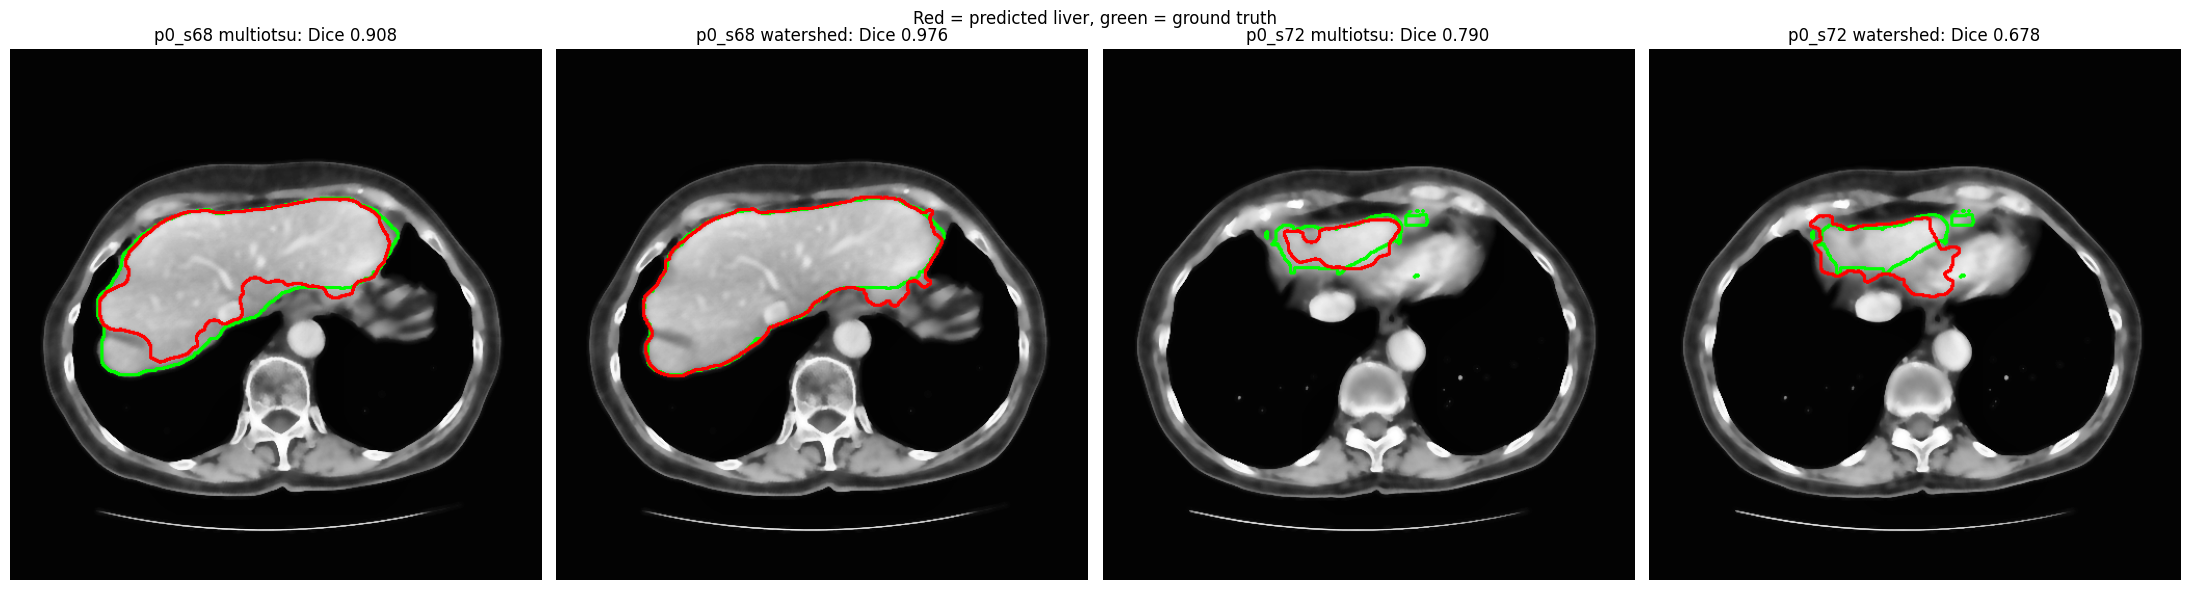

In [6]:
def overlay(img, pred, gt):
    rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    for mask, colour in [(gt, (0, 255, 0)), (pred, (255, 0, 0))]:
        contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, contours, -1, colour, 2)
    return rgb

ws = results[results.method == "watershed"].set_index("slice")["Dice"]
best_sid, worst_sid = ws.idxmax(), ws.idxmin()
fig, ax = plt.subplots(1, 4, figsize=(22, 6))
for a, (s, method) in zip(ax, [(best_sid, "multiotsu"), (best_sid, "watershed"),
                               (worst_sid, "multiotsu"), (worst_sid, "watershed")]):
    _, img, gt = load(f"{ENH}/{s}_enh.png")
    pred = cv2.imread(f"{OUT}/{method}/{s}_liver_pred.png", 0) > 0
    a.imshow(overlay(img, pred, gt)); a.axis("off")
    a.set_title(f"{s} {method}: Dice {dice(pred, gt):.3f}")
plt.suptitle("Red = predicted liver, green = ground truth")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_overlays.png", dpi=120); plt.show()

In [7]:
# ---- failed cases: every slice where the best method scored Dice < 0.7, with the likely reason ----
def failure_reason(pred, gt):
    if pred.sum() == 0:
        return "missed completely: nothing was segmented"
    if gt.sum() < 3000:
        return f"very small liver on this slice ({int(gt.sum())} pixels), near the top or bottom of the organ"
    if pred.sum() > 1.5 * gt.sum():
        return "over-segmentation: the mask leaked into neighbouring tissue"
    if pred.sum() < 0.6 * gt.sum():
        return "under-segmentation: only part of the liver was found"
    return "boundary mismatch: right place, but the outline differs from the ground truth"

best_method = results.groupby("method")["Dice"].mean().idxmax()
best = results[results.method == best_method].sort_values("Dice")
failed = best[best.Dice < 0.7]
lines = [f"# Phase 2 failed cases: {NAME} (liver segmentation)", "",
         f"Best method: **{best_method}** (mean Dice {best.Dice.mean():.3f}). Slices with Dice < 0.7: {len(failed)} of {len(best)}.", "",
         "| Slice | Dice ({}) | Ground-truth pixels | Predicted pixels | Likely reason |".format(best_method),
         "|---|---|---|---|---|"]
for _, row in failed.iterrows():
    r = load(f"{ENH}/{row.slice}_enh.png")
    img, gt = r[1], r[-1]
    pred = cv2.imread(f"{OUT}/{best_method}/{row.slice}_liver_pred.png", 0) > 0
    lines.append(f"| {row.slice} | {row.Dice:.3f} | {int(gt.sum())} | {int(pred.sum())} | {failure_reason(pred, gt)} |")
for _, row in failed.head(3).iterrows():                       # save overlays of the 3 worst
    r = load(f"{ENH}/{row.slice}_enh.png")
    img, gt = r[1], r[-1]
    pred = cv2.imread(f"{OUT}/{best_method}/{row.slice}_liver_pred.png", 0) > 0
    cv2.imwrite(f"{FAILED}/{NAME}_{row.slice}_{best_method}_overlay.png", cv2.cvtColor(overlay(img, pred, gt), cv2.COLOR_RGB2BGR))
if failed.empty:
    lines.append("| - | - | - | - | no slice below 0.7 |")
lines += ["", "Overlay images of the 3 worst slices are saved next to this file (red = predicted, green = ground truth)."]
open(f"{FAILED}/{NAME}_phase2_failed_cases.md", "w").write("\n".join(lines))
print("\n".join(lines))

# Phase 2 failed cases: sama (liver segmentation)

Best method: **watershed** (mean Dice 0.913). Slices with Dice < 0.7: 1 of 16.

| Slice | Dice (watershed) | Ground-truth pixels | Predicted pixels | Likely reason |
|---|---|---|---|---|
| p0_s72 | 0.678 | 4641 | 7110 | over-segmentation: the mask leaked into neighbouring tissue |

Overlay images of the 3 worst slices are saved next to this file (red = predicted, green = ground truth).
